<a href="https://colab.research.google.com/github/anushka24-student/Pneumonia-Detector/blob/main/pneumonia_detector.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
files.upload()

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia
!unzip chest-xray-pneumonia.zip -d chest_xray/

print("Dataset downloaded!")

Saving ._chest_xray to ._chest_xray
cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
chest-xray-pneumonia.zip: Skipping, found more recently modified local copy (use --force to force download)
Archive:  chest-xray-pneumonia.zip
replace chest_xray/chest_xray/__MACOSX/._chest_xray? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [ ]:
import numpy as np
from tensorflow.keras.models import Sequential
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import os
import gradio as gr
import warnings
warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Conv2D, MaxPooling2D,
                            Flatten, Dense, Dropout,
                            BatchNormalization, GlobalAveragePooling2D)
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import (EarlyStopping,
                            ReduceLROnPlateau, ModelCheckpoint)
from tensorflow.keras.applications import VGG16
from sklearn.metrics import (classification_report,
                             confusion_matrix, roc_auc_score,
                             roc_curve)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
base_path = 'chest_xray/chest_xray'

for split in ['train', 'test', 'val']:
    for label in ['NORMAL', 'PNEUMONIA']:
        path = f'{base_path}/{split}/{label}'
        count = len(os.listdir(path))
        print(f"{split}/{label}: {count} images")

train/NORMAL: 1341 images
train/PNEUMONIA: 3875 images
test/NORMAL: 234 images
test/PNEUMONIA: 390 images
val/NORMAL: 8 images
val/PNEUMONIA: 8 images


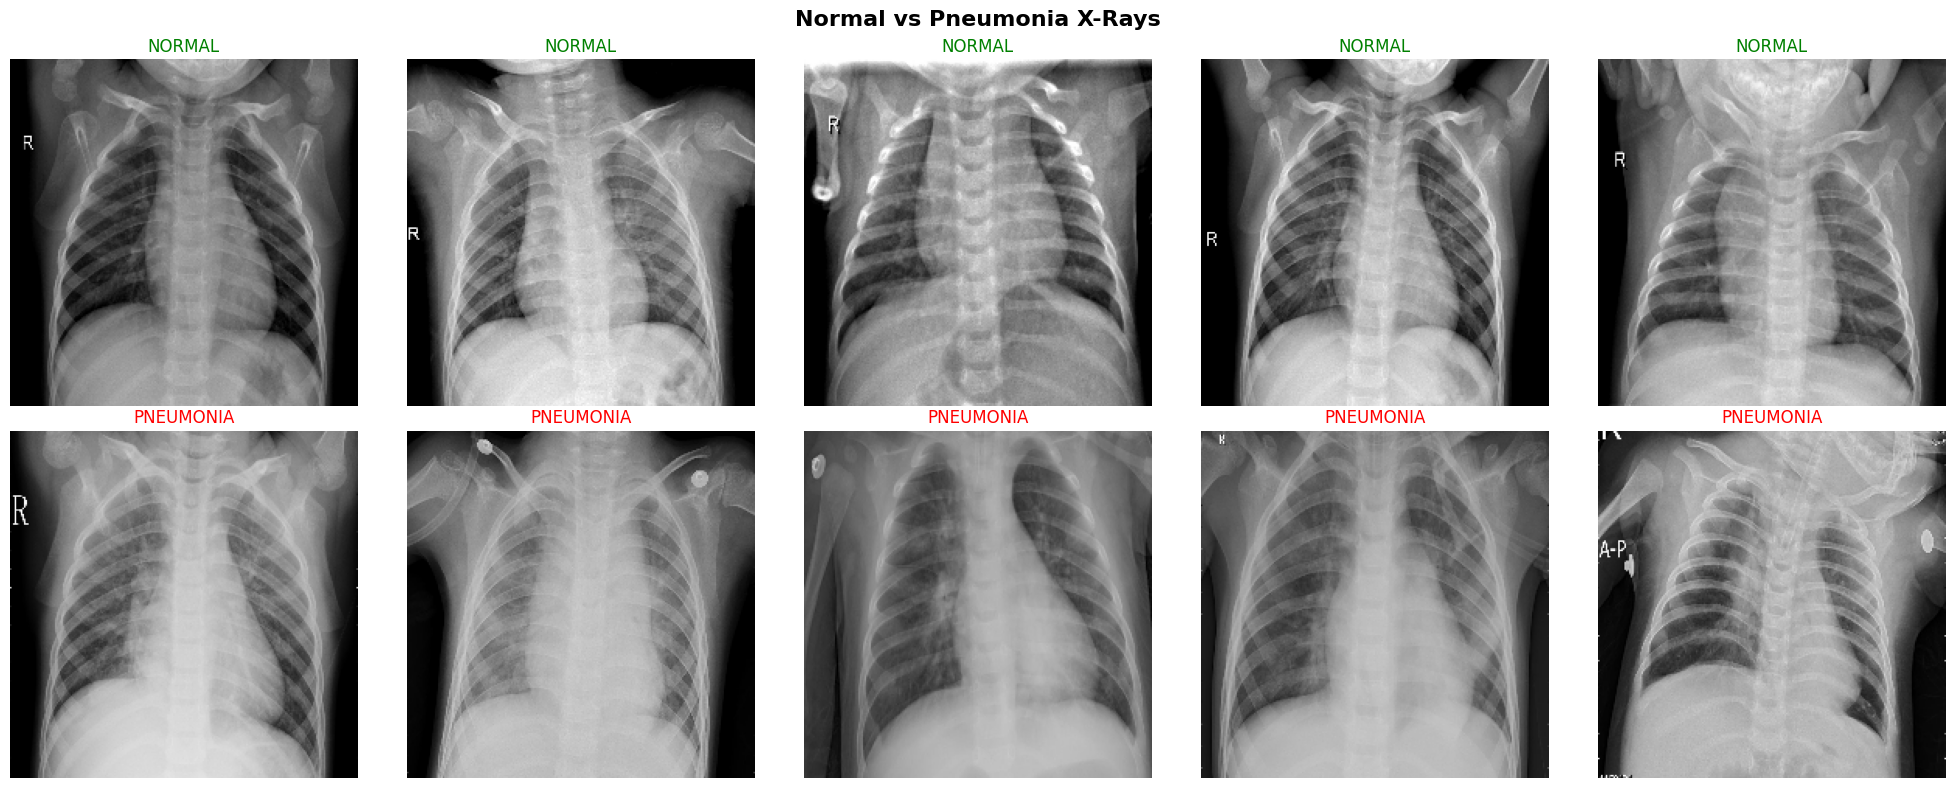

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8))


normal_path = f'{base_path}/train/NORMAL/'
normal_images = os.listdir(normal_path)[:5]

for i, img_name in enumerate(normal_images):
    img = cv2.imread(normal_path + img_name)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (224, 224))
    axes[0][i].imshow(img, cmap='gray')
    axes[0][i].set_title('NORMAL',
                          color='green', fontsize=12)
    axes[0][i].axis('off')


pneumonia_path = f'{base_path}/train/PNEUMONIA/'
pneumonia_images = os.listdir(pneumonia_path)[:5]

for i, img_name in enumerate(pneumonia_images):
    img = cv2.imread(pneumonia_path + img_name)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (224, 224))
    axes[1][i].imshow(img, cmap='gray')
    axes[1][i].set_title('PNEUMONIA',
                          color='red', fontsize=12)
    axes[1][i].axis('off')

plt.suptitle('Normal vs Pneumonia X-Rays',
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('sample_xrays.png', dpi=150)
plt.show()

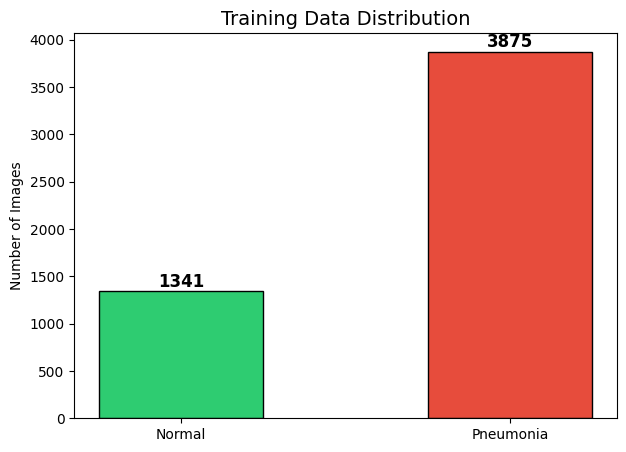

In [ ]:
train_normal = len(os.listdir(
    f'{base_path}/train/NORMAL'))
train_pneumonia = len(os.listdir(
    f'{base_path}/train/PNEUMONIA'))

labels = ['Normal', 'Pneumonia']
values = [train_normal, train_pneumonia]
colors = ['#2ecc71', '#e74c3c']

plt.figure(figsize=(7,5))
bars = plt.bar(labels, values, color=colors,
               edgecolor='black', width=0.5)
plt.title('Training Data Distribution', fontsize=14)
plt.ylabel('Number of Images')

for bar, val in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 50,
             str(val), ha='center',
             fontsize=12, fontweight='bold')

plt.savefig('class_distribution.png', dpi=150)
plt.show()

In [ ]:
# Training with augmentation
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    zoom_range=0.1,
    shear_range=0.1,
    fill_mode='nearest'
)

# Validation and test — only rescale
test_datagen = ImageDataGenerator(rescale=1./255)

# Load data
train_data = train_datagen.flow_from_directory(
    f'{base_path}/train',
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    color_mode='rgb'
)

val_data = test_datagen.flow_from_directory(
    f'{base_path}/val',
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary'
)

test_data = test_datagen.flow_from_directory(
    f'{base_path}/test',
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    shuffle=False   # important for evaluation
)

print("Class indices:", train_data.class_indices)
# NORMAL=0, PNEUMONIA=1

Found 5216 images belonging to 2 classes.
Found 16 images belonging to 2 classes.
Found 624 images belonging to 2 classes.
Class indices: {'NORMAL': 0, 'PNEUMONIA': 1}


In [ ]:
# Load VGG16 without top classification layers
base_model = VGG16(
    weights='imagenet',    # pre-trained on 1M images
    include_top=False,     # remove final layers
    input_shape=(224, 224, 3)
)

# Freeze base model layers
# (don't retrain — keep ImageNet knowledge)
base_model.trainable = False

print("VGG16 loaded!")
print(f"Total layers: {len(base_model.layers)}")

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
VGG16 loaded!
Total layers: 19


In [ ]:
model = Sequential([
    base_model,
    # Include the VGG16 base model here

    # Our custom classifier on top
    GlobalAveragePooling2D(),
    Dense(256, activation='relu'),
    BatchNormalization(),
    Dropout(0.5),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')  # binary output
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,880,065 (56.76 MB)

 Trainable params: 164,865 (644.00 KB)

 Non-trainable params: 14,715,200 (56.13 MB)

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
              learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=['accuracy',
             tf.keras.metrics.AUC(name='auc'),
             tf.keras.metrics.Precision(name='precision'),
             tf.keras.metrics.Recall(name='recall')]
)

In [ ]:
early_stop = EarlyStopping(
    monitor='val_auc',
    patience=5,
    restore_best_weights=True,
    mode='max'
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_lr=0.000001
)

checkpoint = ModelCheckpoint(
    'best_pneumonia_model.h5',
    monitor='val_auc',
    save_best_only=True,
    mode='max'
)

In [ ]:
history = model.fit(
    train_data,
    epochs=20,
    validation_data=val_data,
    callbacks=[early_stop, reduce_lr, checkpoint],
    class_weight={0: 1.0, 1: 0.6}
    # handles class imbalance
)

print("Training Complete!")

Epoch 1/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 660ms/step - accuracy: 0.7575 - auc: 0.8066 - loss: 0.3549 - precision: 0.8706 - recall: 0.7904

163/163 ━━━━━━━━━━━━━━━━━━━━ 136s 729ms/step - accuracy: 0.8215 - auc: 0.8977 - loss: 0.2819 - precision: 0.9225 - recall: 0.8294 - val_accuracy: 0.6250 - val_auc: 0.9062 - val_loss: 0.5968 - val_precision: 0.5714 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 2/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 658ms/step - accuracy: 0.8871 - auc: 0.9558 - loss: 0.1920 - precision: 0.9600 - recall: 0.8853

163/163 ━━━━━━━━━━━━━━━━━━━━ 108s 661ms/step - accuracy: 0.8940 - auc: 0.9534 - loss: 0.1919 - precision: 0.9576 - recall: 0.8970 - val_accuracy: 0.6250 - val_auc: 0.9141 - val_loss: 0.5850 - val_precision: 0.5714 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 3/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 659ms/step - accuracy: 0.9057 - auc: 0.9597 - loss: 0.1749 - precision: 0.9591 - recall: 0.9132

163/163 ━━━━━━━━━━━━━━━━━━━━ 108s 662ms/step - accuracy: 0.9110 - auc: 0.9624 - loss: 0.1694 - precision: 0.9596 - recall: 0.9190 - val_accuracy: 0.7500 - val_auc: 0.9219 - val_loss: 0.5129 - val_precision: 0.6667 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 4/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 653ms/step - accuracy: 0.9229 - auc: 0.9699 - loss: 0.1513 - precision: 0.9638 - recall: 0.9297

163/163 ━━━━━━━━━━━━━━━━━━━━ 107s 656ms/step - accuracy: 0.9212 - auc: 0.9699 - loss: 0.1500 - precision: 0.9661 - recall: 0.9265 - val_accuracy: 0.6875 - val_auc: 0.9375 - val_loss: 0.7964 - val_precision: 0.6154 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 5/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 107s 654ms/step - accuracy: 0.9293 - auc: 0.9748 - loss: 0.1377 - precision: 0.9667 - recall: 0.9370 - val_accuracy: 0.7500 - val_auc: 0.9375 - val_loss: 0.4530 - val_precision: 0.6667 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 6/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 671ms/step - accuracy: 0.9309 - auc: 0.9761 - loss: 0.1351 - precision: 0.9725 - recall: 0.9333

163/163 ━━━━━━━━━━━━━━━━━━━━ 145s 674ms/step - accuracy: 0.9314 - auc: 0.9762 - loss: 0.1330 - precision: 0.9693 - recall: 0.9373 - val_accuracy: 0.7500 - val_auc: 0.9531 - val_loss: 0.5303 - val_precision: 0.6667 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 7/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 107s 657ms/step - accuracy: 0.9298 - auc: 0.9769 - loss: 0.1307 - precision: 0.9677 - recall: 0.9368 - val_accuracy: 0.7500 - val_auc: 0.9531 - val_loss: 0.5677 - val_precision: 0.6667 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 8/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 106s 651ms/step - accuracy: 0.9321 - auc: 0.9776 - loss: 0.1274 - precision: 0.9676 - recall: 0.9401 - val_accuracy: 0.7500 - val_auc: 0.9375 - val_loss: 0.5353 - val_precision: 0.6667 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 9/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 108s 660ms/step - accuracy: 0.9388 - auc: 0.9814 - loss: 0.1169 - precision: 0.9719 - recall: 0.9450 - val_accuracy: 0.7500 - val_auc: 0.9375 - val_l

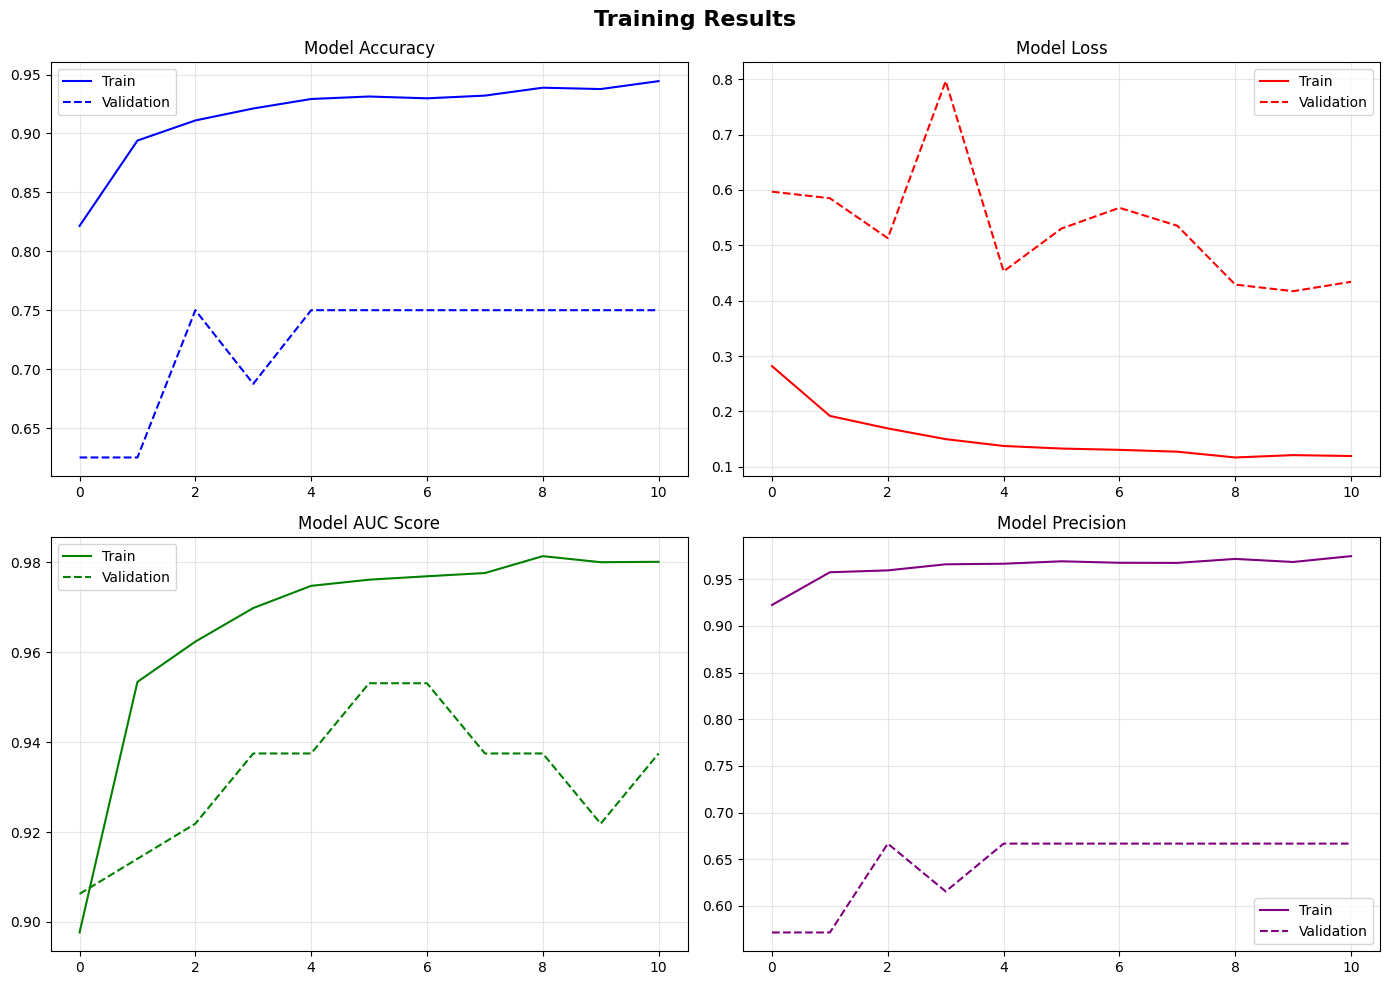

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

metrics = ['accuracy', 'loss', 'auc', 'precision']
titles = ['Accuracy', 'Loss', 'AUC Score', 'Precision']
colors = ['blue', 'red', 'green', 'purple']

for i, (metric, title, color) in enumerate(
        zip(metrics, titles, colors)):
    row, col = i // 2, i % 2
    axes[row][col].plot(
        history.history[metric],
        label='Train', color=color)
    axes[row][col].plot(
        history.history[f'val_{metric}'],
        label='Validation',
        color=color, linestyle='--')
    axes[row][col].set_title(f'Model {title}')
    axes[row][col].legend()
    axes[row][col].grid(True, alpha=0.3)

plt.suptitle('Training Results', fontsize=16,
             fontweight='bold')
plt.tight_layout()
plt.savefig('training_curves.png', dpi=150)
plt.show()

In [ ]:
results = model.evaluate(test_data, verbose=1)
print(f"\nTest Accuracy:  {results[1]:.4f}")
print(f"Test AUC:       {results[2]:.4f}")
print(f"Test Precision: {results[3]:.4f}")
print(f"Test Recall:    {results[4]:.4f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 7s 253ms/step - accuracy: 0.9038 - auc: 0.9483 - loss: 0.2808 - precision: 0.8873 - recall: 0.9692

Test Accuracy:  0.9038
Test AUC:       0.9483
Test Precision: 0.8873
Test Recall:    0.9692


20/20 ━━━━━━━━━━━━━━━━━━━━ 13s 528ms/step


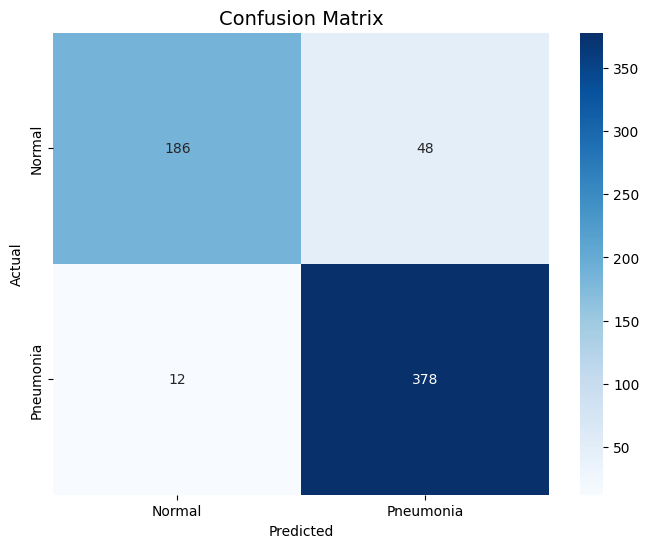

              precision    recall  f1-score   support

      Normal       0.94      0.79      0.86       234
   Pneumonia       0.89      0.97      0.93       390

    accuracy                           0.90       624
   macro avg       0.91      0.88      0.89       624
weighted avg       0.91      0.90      0.90       624



In [ ]:
y_pred_prob = model.predict(test_data)
y_pred = (y_pred_prob > 0.5).astype(int).flatten()
y_true = test_data.classes

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=['Normal', 'Pneumonia'],
            yticklabels=['Normal', 'Pneumonia'])
plt.title('Confusion Matrix', fontsize=14)
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()

print(classification_report(y_true, y_pred,
      target_names=['Normal', 'Pneumonia']))

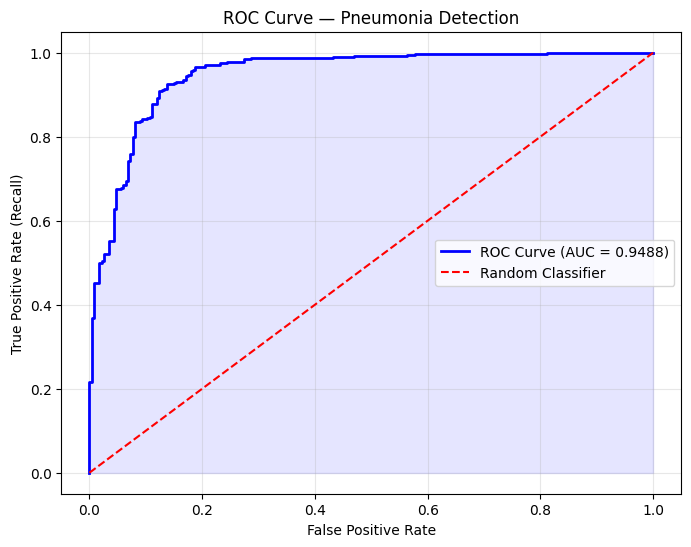

In [ ]:
fpr, tpr, _ = roc_curve(y_true, y_pred_prob)
auc_score = roc_auc_score(y_true, y_pred_prob)

plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, color='blue',
         linewidth=2,
         label=f'ROC Curve (AUC = {auc_score:.4f})')
plt.plot([0,1], [0,1], color='red',
         linestyle='--', label='Random Classifier')
plt.fill_between(fpr, tpr, alpha=0.1, color='blue')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve — Pneumonia Detection')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('roc_curve.png', dpi=150)
plt.show()

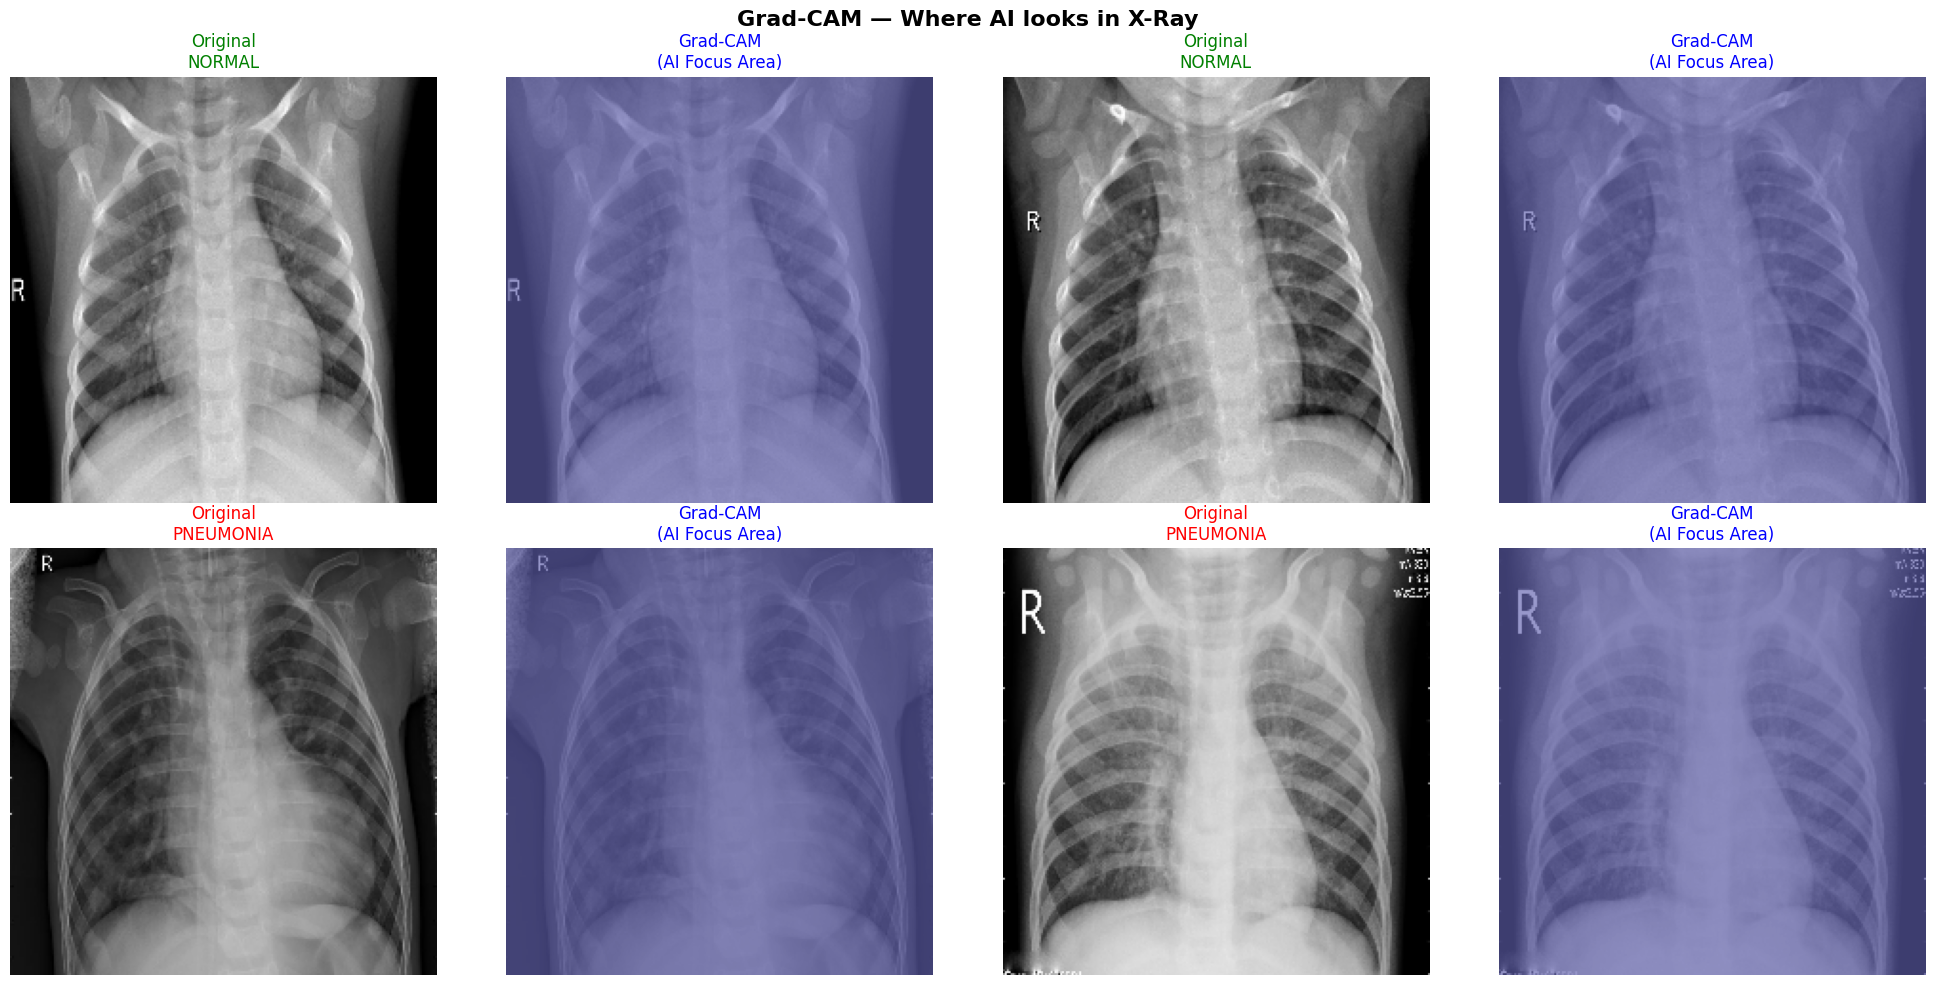

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt # Added this line
import os # Added this line
import cv2 # Assuming cv2 is imported elsewhere or added to the cell

def get_gradcam_heatmap(model, img_array, layer_name):
    # Store original trainable state of the base model
    original_trainable_state = model.layers[0].trainable
    # Temporarily set base model to trainable=True to allow gradient computation
    # This is crucial for GradientTape to track operations within the base_model (VGG16)
    model.layers[0].trainable = True

    # Define the input for our Grad-CAM model, matching the original model's input shape
    # model.input_shape gives (None, H, W, C), so [1:] gets (H, W, C)
    gradcam_input = tf.keras.Input(shape=model.input_shape[1:])

    # Get the output of the VGG16 base model (model.layers[0]) when fed with gradcam_input
    # This `x` is the feature map from the VGG16 part
    x = model.layers[0](gradcam_input)

    # Get the specific convolutional layer from the base model (VGG16)
    target_conv_layer = model.layers[0].get_layer(layer_name)
    # Get its output by explicitly calling it with the current tensor `x`
    conv_output_for_gradcam = target_conv_layer(x)

    # Now, pass the output of the base_model (`x`) through the rest of the classifier layers.
    # These are model.layers[1] through model.layers[7]
    classifier_path_output = x # Start with the output of the base_model
    for layer in model.layers[1:]: # Iterate from GlobalAveragePooling2D to the final Dense layer
        classifier_path_output = layer(classifier_path_output)

    # Create the new Grad-CAM model with the correct inputs and outputs
    grad_model = tf.keras.models.Model(
        inputs=gradcam_input,
        outputs=[conv_output_for_gradcam, classifier_path_output]
    )

    with tf.GradientTape() as tape:
        # Pass the input image array through the grad_model
        (conv_outputs, predictions) = grad_model(img_array)
        # Explicitly watch the tensor of the convolutional layer's output
        tape.watch(conv_outputs)

        # Assuming predictions are for class 1 (Pneumonia) or class 0 (Normal)
        # and the model's last layer is sigmoid, predictions[:, 0] gives probability of Pneumonia.
        loss = predictions[:, 0]

    grads = tape.gradient(loss, conv_outputs)

    # Restore original trainable state immediately after gradient computation
    model.layers[0].trainable = original_trainable_state

    # Handle the case where gradients might be None (though hopefully fixed by temporarily making base model trainable)
    if grads is None:
        print(f"Warning: Gradients are None for layer {layer_name}. Returning empty heatmap.")
        return np.zeros(conv_outputs.shape[1:3]) # Return a 2D empty heatmap

    # Compute weighted averages of activation maps
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    heatmap = conv_outputs[0] @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()

# Visualize on sample images
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
sample_paths = {
    'NORMAL': os.listdir(
        f'{base_path}/test/NORMAL')[:2],
    'PNEUMONIA': os.listdir(
        f'{base_path}/test/PNEUMONIA')[:2]
}

for row, (label, images) in enumerate(
        sample_paths.items()):
    for col, img_name in enumerate(images):
        folder = f'{base_path}/test/{label}/'
        img = cv2.imread(folder + img_name)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img_resized = cv2.resize(img, (224, 224))
        img_array = np.expand_dims(
            img_resized/255.0, axis=0)

        # Original image
        axes[row][col*2].imshow(img_resized)
        axes[row][col*2].set_title(
            f'Original\n{label}',
            color='green' if label=='NORMAL' else 'red')
        axes[row][col*2].axis('off')

        # Grad-CAM heatmap
        heatmap = get_gradcam_heatmap(
            model, img_array.astype(np.float32),
            'block5_conv3')
        heatmap_resized = cv2.resize(
            heatmap, (224, 224))
        axes[row][col*2+1].imshow(
            img_resized, alpha=0.6)
        axes[row][col*2+1].imshow(
            heatmap_resized, cmap='jet',
            alpha=0.4)
        axes[row][col*2+1].set_title(
            'Grad-CAM\n(AI Focus Area)',
            color='blue')
        axes[row][col*2+1].axis('off')

plt.suptitle('Grad-CAM — Where AI looks in X-Ray',
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('gradcam.png', dpi=150)
plt.show()